## Weekday and Weekend Mode Patterns (Flag 20)

### Dataset Overview

Constructed case: distances and speeds use matched-road coordinates. Consecutive duplicate road positions are removed; non-cycling routes retain prefixes of their existing road polylines. Weekend car routes remain 1.1--3 km. Smooth, variable mode-conditioned speeds determine nanosecond timestamps and acceleration. Constructed user IDs are reassigned where needed to avoid overlapping trips and allow between-trip transfers; prior_constructed_user_id retains the earlier alias. The sampled weekday dates are Mondays and the sampled weekend dates are Saturdays; the insights describe this constructed sample, not population-wide behaviour.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Investigate travel patterns of the users between weekdays and weekend, considering travel modes.

Role: Urban mobility analyst


Category: Day type, travel mode, time, distance, and spatial extent


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)
df["departure_time"] = pd.to_datetime(df["departure_time"], format="mixed")
df["arrival_time"] = pd.to_datetime(df["arrival_time"], format="mixed")

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do travel-mode shares differ between weekdays and weekends?

#### Analysis action

Compare normalized mode distributions by day type and verify the intended aggregate shares.

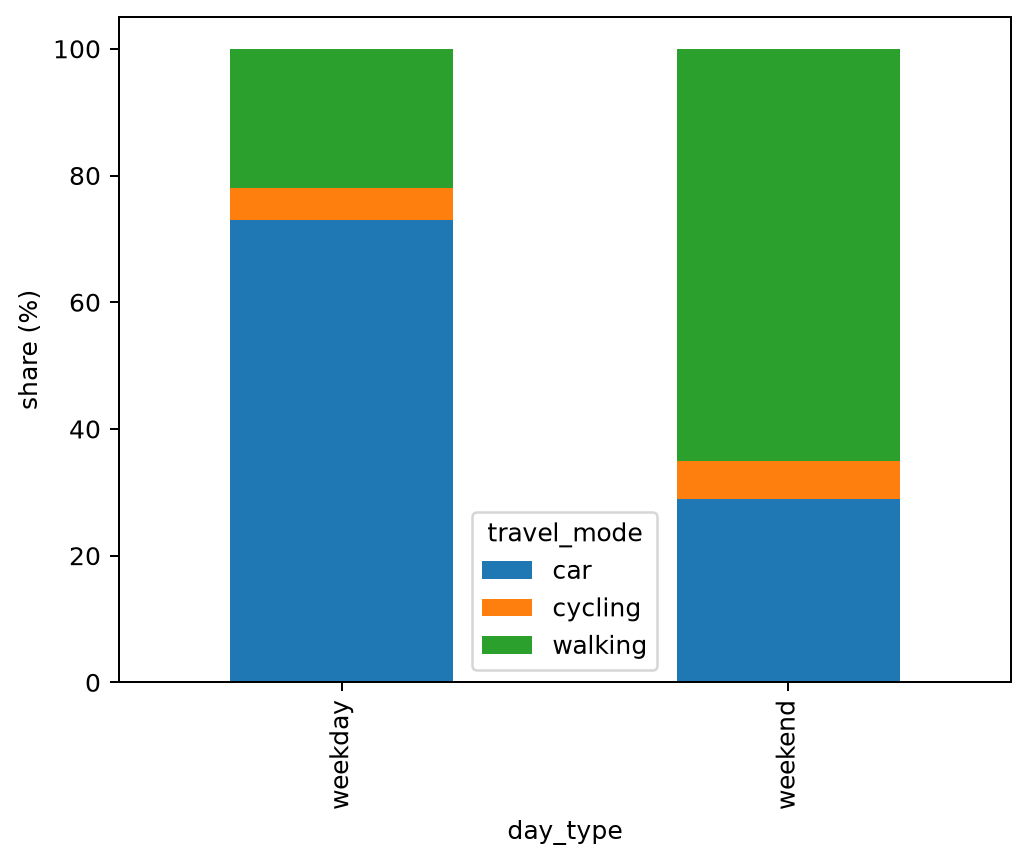

In [ ]:
tab = pd.crosstab(df.day_type, df.travel_mode, normalize="index") * 100
print(tab.round(1))
tab.plot.bar(stacked=True)
plt.ylabel("share (%)")
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex20_insight_1",
  "insight": "Car trips dominate weekday travel, while walking accounts for a noticeably larger share of trips on weekends. ",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Weekday and Weekend Mode Patterns: Insight 1",
    "description": "The map uses NYC road geometry, including the non-retracing cycling loop routed over OpenStreetMap roads; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "How do travel-mode shares differ between weekdays and weekends?",
  "actionable_insight": "Compare normalized mode distributions by day type and verify the intended aggregate shares.",
  "code": "tab=pd.crosstab(df.day_type,df.travel_mode,normalize='index')*100; print(tab.round(1)); tab.plot.bar(stacked=True); plt.ylabel('share (%)'); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "transport_mode",
    "matched_road_position"
  ]
}

### **Question 2**: How do car-trip distance and departure-time concentration differ by day type?

#### Analysis action

Compare car-only distance distributions and normalized departure-hour distributions in separate panels.

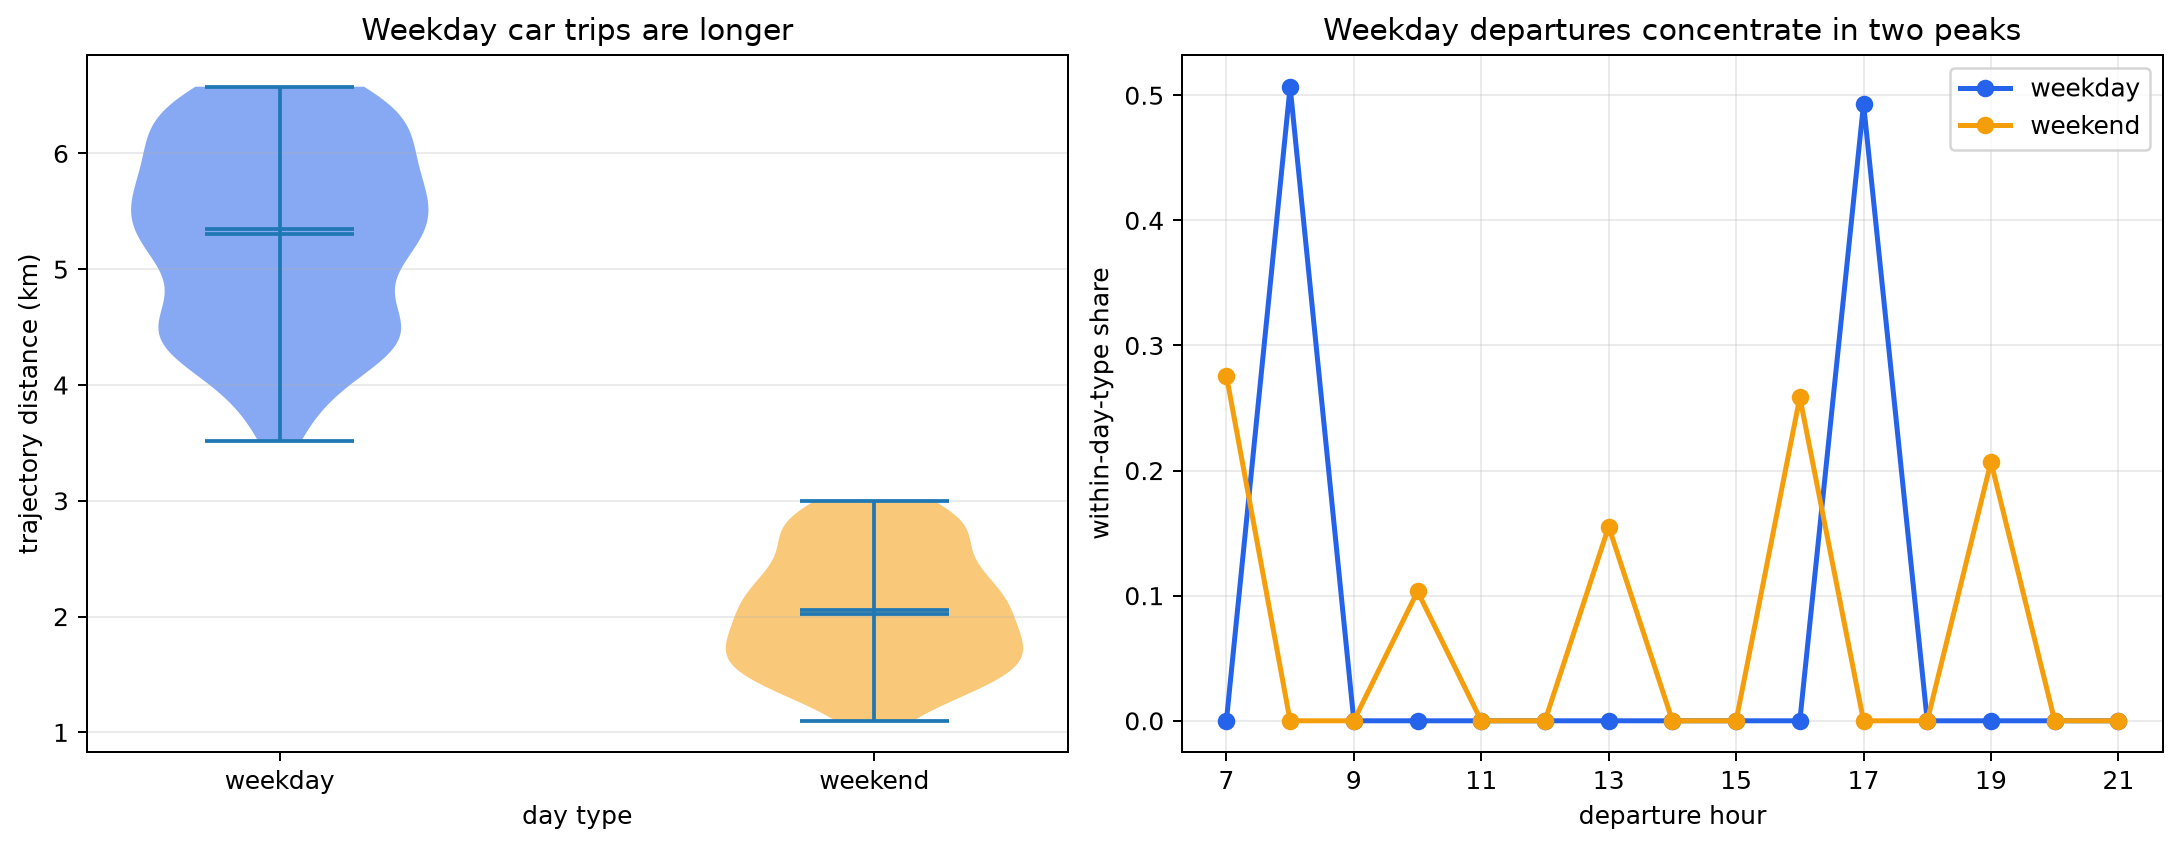

In [ ]:
c = df[df.travel_mode.eq("car")].copy()
c["hour"] = c.departure_time.dt.hour
summary = c.groupby("day_type").agg(
    trips=("trajectory_id", "size"),
    mean_distance_km=("trajectory_distance_km", "mean"),
    median_distance_km=("trajectory_distance_km", "median"),
    occupied_hours=("hour", "nunique"),
)
print(summary.round(2))
hours = pd.crosstab(c.hour, c.day_type, normalize="columns").reindex(
    range(7, 22), fill_value=0
)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
vals = [c[c.day_type.eq(k)].trajectory_distance_km for k in ["weekday", "weekend"]]
parts = ax[0].violinplot(vals, showmeans=True, showmedians=True)
for body, color in zip(parts["bodies"], ["#2563eb", "#f59e0b"]):
    body.set_facecolor(color)
    body.set_alpha(0.55)
ax[0].set_xticks([1, 2], ["weekday", "weekend"])
ax[0].set(
    title="Weekday car trips are longer",
    xlabel="day type",
    ylabel="trajectory distance (km)",
)
ax[0].grid(axis="y", alpha=0.25)
for k, color in [("weekday", "#2563eb"), ("weekend", "#f59e0b")]:
    ax[1].plot(hours.index, hours[k], marker="o", linewidth=2, label=k, color=color)
ax[1].set(
    title="Weekday departures concentrate in two peaks",
    xlabel="departure hour",
    ylabel="within-day-type share",
)
ax[1].set_xticks(range(7, 22, 2))
ax[1].legend()
ax[1].grid(alpha=0.25)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex20_insight_2",
  "insight": "Weekday car trips are longer and occur within more concentrated time periods, whereas weekend car trips are shorter and distributed more broadly across the day.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Weekday and Weekend Mode Patterns: Insight 2",
    "description": "The map uses NYC road geometry, including the non-retracing cycling loop routed over OpenStreetMap roads; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "How do car-trip distance and departure-time concentration differ by day type?",
  "actionable_insight": "Compare car-only distance distributions and normalized departure-hour distributions in separate panels.",
  "code": "c=df[df.travel_mode.eq('car')].copy();c['hour']=c.departure_time.dt.hour\nsummary=c.groupby('day_type').agg(trips=('trajectory_id','size'),mean_distance_km=('trajectory_distance_km','mean'),median_distance_km=('trajectory_distance_km','median'),occupied_hours=('hour','nunique'));print(summary.round(2))\nhours=pd.crosstab(c.hour,c.day_type,normalize='columns').reindex(range(7,22),fill_value=0)\nfig,ax=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)\nvals=[c[c.day_type.eq(k)].trajectory_distance_km for k in ['weekday','weekend']];parts=ax[0].violinplot(vals,showmeans=True,showmedians=True)\nfor body,color in zip(parts['bodies'],['#2563eb','#f59e0b']):body.set_facecolor(color);body.set_alpha(.55)\nax[0].set_xticks([1,2],['weekday','weekend']);ax[0].set(title='Weekday car trips are longer',xlabel='day type',ylabel='trajectory distance (km)');ax[0].grid(axis='y',alpha=.25)\nfor k,color in [('weekday','#2563eb'),('weekend','#f59e0b')]:ax[1].plot(hours.index,hours[k],marker='o',linewidth=2,label=k,color=color)\nax[1].set(title='Weekday departures concentrate in two peaks',xlabel='departure hour',ylabel='within-day-type share');ax[1].set_xticks(range(7,22,2));ax[1].legend();ax[1].grid(alpha=.25);plt.show()",
  "insight_type": "temporal_dynamics",
  "insight_value": {
    "weekend_car_distance_range_km": [
      1.1,
      3.0
    ],
    "weekend_car_trip_count": 58,
    "weekday_car_mean_distance_km": 5.305848,
    "weekend_car_mean_distance_km": 2.053534
  },
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "transport_mode",
    "gps_position",
    "matched_road_position"
  ]
}

### **Question 3**: Do weekend walking trajectories cover a wider spatial range at similarly low speeds?

#### Analysis action

Compare the geographic convex-hull footprint of all walking points and the trajectory-level walking-speed distributions by day type.

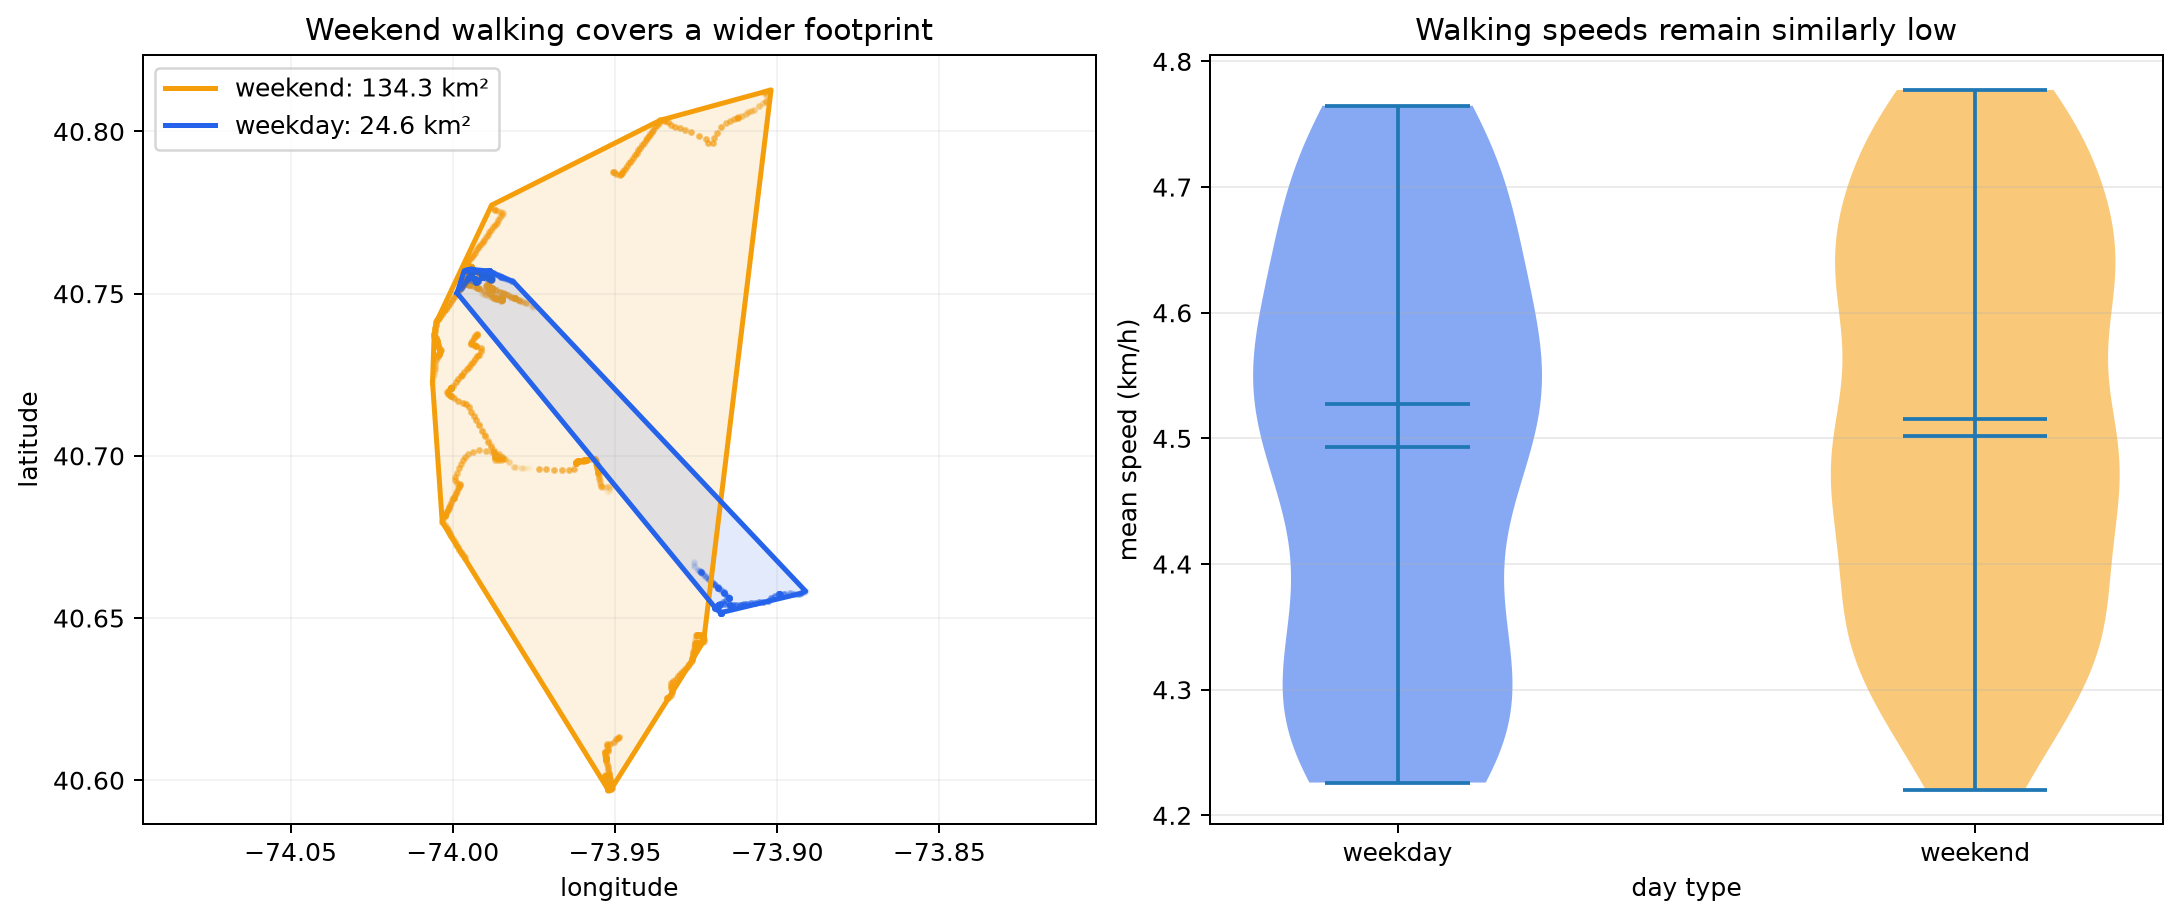

In [ ]:
w = df[df.travel_mode.eq("walking")].copy()
wp = user_df[user_df.trajectory_id.isin(w.trajectory_id)].merge(
    w[["trajectory_id", "day_type"]], on="trajectory_id", suffixes=("", "_trip")
)


def hull(xy):
    pts = sorted(set(map(tuple, xy)))
    if len(pts) < 3:
        return pts

    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

    lo = []
    for p in pts:
        while len(lo) >= 2 and cross(lo[-2], lo[-1], p) <= 0:
            lo.pop()
        lo.append(p)
    hi = []
    for p in reversed(pts):
        while len(hi) >= 2 and cross(hi[-2], hi[-1], p) <= 0:
            hi.pop()
        hi.append(p)
    return lo[:-1] + hi[:-1]


def area_km2(poly, reference_lat):
    if len(poly) < 3:
        return 0
    lon0, lat0 = poly[0]
    q = [
        ((x - lon0) * 111.320 * np.cos(np.radians(reference_lat)), (y - lat0) * 110.574)
        for x, y in poly
    ]
    return abs(
        sum(
            q[i][0] * q[(i + 1) % len(q)][1] - q[(i + 1) % len(q)][0] * q[i][1]
            for i in range(len(q))
        )
        / 2
    )


fig, ax = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
areas = {}
for day, color in [("weekend", "#f59e0b"), ("weekday", "#2563eb")]:
    q = wp[wp.day_type.eq(day)]
    poly = hull(q[["matched_road_longitude", "matched_road_latitude"]].to_numpy())
    areas[day] = area_km2(poly, q.matched_road_latitude.mean())
    closed = poly + [poly[0]]
    ax[0].scatter(
        q.matched_road_longitude, q.matched_road_latitude, s=3, alpha=0.05, color=color
    )
    ax[0].fill([x for x, y in closed], [y for x, y in closed], color=color, alpha=0.13)
    ax[0].plot(
        [x for x, y in closed],
        [y for x, y in closed],
        color=color,
        linewidth=2,
        label=f"{day}: {areas[day]:.1f} km²",
    )
ax[0].set(
    title="Weekend walking covers a wider footprint",
    xlabel="longitude",
    ylabel="latitude",
)
ax[0].set_aspect("equal", adjustable="datalim")
ax[0].legend()
ax[0].grid(alpha=0.15)
vals = [w[w.day_type.eq(k)].mean_speed_kmh for k in ["weekday", "weekend"]]
parts = ax[1].violinplot(vals, showmeans=True, showmedians=True)
for body, color in zip(parts["bodies"], ["#2563eb", "#f59e0b"]):
    body.set_facecolor(color)
    body.set_alpha(0.55)
ax[1].set_xticks([1, 2], ["weekday", "weekend"])
ax[1].set(
    title="Walking speeds remain similarly low",
    xlabel="day type",
    ylabel="mean speed (km/h)",
)
ax[1].grid(axis="y", alpha=0.25)
print(
    w.groupby("day_type")
    .agg(
        trips=("trajectory_id", "size"),
        routes=("source_trajectory_id", "nunique"),
        mean_speed_kmh=("mean_speed_kmh", "mean"),
    )
    .round(3)
)
print("walking footprint area (km²)", {k: round(v, 2) for k, v in areas.items()})
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex20_insight_3",
  "insight": "Weekend walking trips cover a wider spatial range than weekday walking trips, despite maintaining similarly low travel speeds.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Weekday and Weekend Mode Patterns: Insight 3",
    "description": "The map uses NYC road geometry, including the non-retracing cycling loop routed over OpenStreetMap roads; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Do weekend walking trajectories cover a wider spatial range at similarly low speeds?",
  "actionable_insight": "Compare the geographic convex-hull footprint of all walking points and the trajectory-level walking-speed distributions by day type.",
  "code": "w=df[df.travel_mode.eq('walking')].copy();wp=user_df[user_df.trajectory_id.isin(w.trajectory_id)].merge(w[['trajectory_id','day_type']],on='trajectory_id',suffixes=('','_trip'))\ndef hull(xy):\n    pts=sorted(set(map(tuple,xy)))\n    if len(pts)<3:return pts\n    def cross(o,a,b):return (a[0]-o[0])*(b[1]-o[1])-(a[1]-o[1])*(b[0]-o[0])\n    lo=[]\n    for p in pts:\n        while len(lo)>=2 and cross(lo[-2],lo[-1],p)<=0:lo.pop()\n        lo.append(p)\n    hi=[]\n    for p in reversed(pts):\n        while len(hi)>=2 and cross(hi[-2],hi[-1],p)<=0:hi.pop()\n        hi.append(p)\n    return lo[:-1]+hi[:-1]\ndef area_km2(poly,reference_lat):\n    if len(poly)<3:return 0\n    lon0,lat0=poly[0];q=[((x-lon0)*111.320*np.cos(np.radians(reference_lat)),(y-lat0)*110.574) for x,y in poly];return abs(sum(q[i][0]*q[(i+1)%len(q)][1]-q[(i+1)%len(q)][0]*q[i][1] for i in range(len(q)))/2)\nfig,ax=plt.subplots(1,2,figsize=(12,5),constrained_layout=True);areas={}\nfor day,color in [('weekend','#f59e0b'),('weekday','#2563eb')]:\n    q=wp[wp.day_type.eq(day)];poly=hull(q[['matched_road_longitude','matched_road_latitude']].to_numpy());areas[day]=area_km2(poly,q.matched_road_latitude.mean());closed=poly+[poly[0]]\n    ax[0].scatter(q.matched_road_longitude,q.matched_road_latitude,s=3,alpha=.05,color=color);ax[0].fill([x for x,y in closed],[y for x,y in closed],color=color,alpha=.13);ax[0].plot([x for x,y in closed],[y for x,y in closed],color=color,linewidth=2,label=f'{day}: {areas[day]:.1f} km²')\nax[0].set(title='Weekend walking covers a wider footprint',xlabel='longitude',ylabel='latitude');ax[0].set_aspect('equal',adjustable='datalim');ax[0].legend();ax[0].grid(alpha=.15)\nvals=[w[w.day_type.eq(k)].mean_speed_kmh for k in ['weekday','weekend']];parts=ax[1].violinplot(vals,showmeans=True,showmedians=True)\nfor body,color in zip(parts['bodies'],['#2563eb','#f59e0b']):body.set_facecolor(color);body.set_alpha(.55)\nax[1].set_xticks([1,2],['weekday','weekend']);ax[1].set(title='Walking speeds remain similarly low',xlabel='day type',ylabel='mean speed (km/h)');ax[1].grid(axis='y',alpha=.25)\nprint(w.groupby('day_type').agg(trips=('trajectory_id','size'),routes=('source_trajectory_id','nunique'),mean_speed_kmh=('mean_speed_kmh','mean')).round(3));print('walking footprint area (km²)',{k:round(v,2) for k,v in areas.items()});plt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "transport_mode",
    "matched_road_position",
    "trajectory_id"
  ]
}

### **Question 4**: Are cycling trips occasional on both day types, and do all of them return to their starting area?

#### Analysis action

Measure cycling shares and verify start-to-end closure for every cycling trajectory.

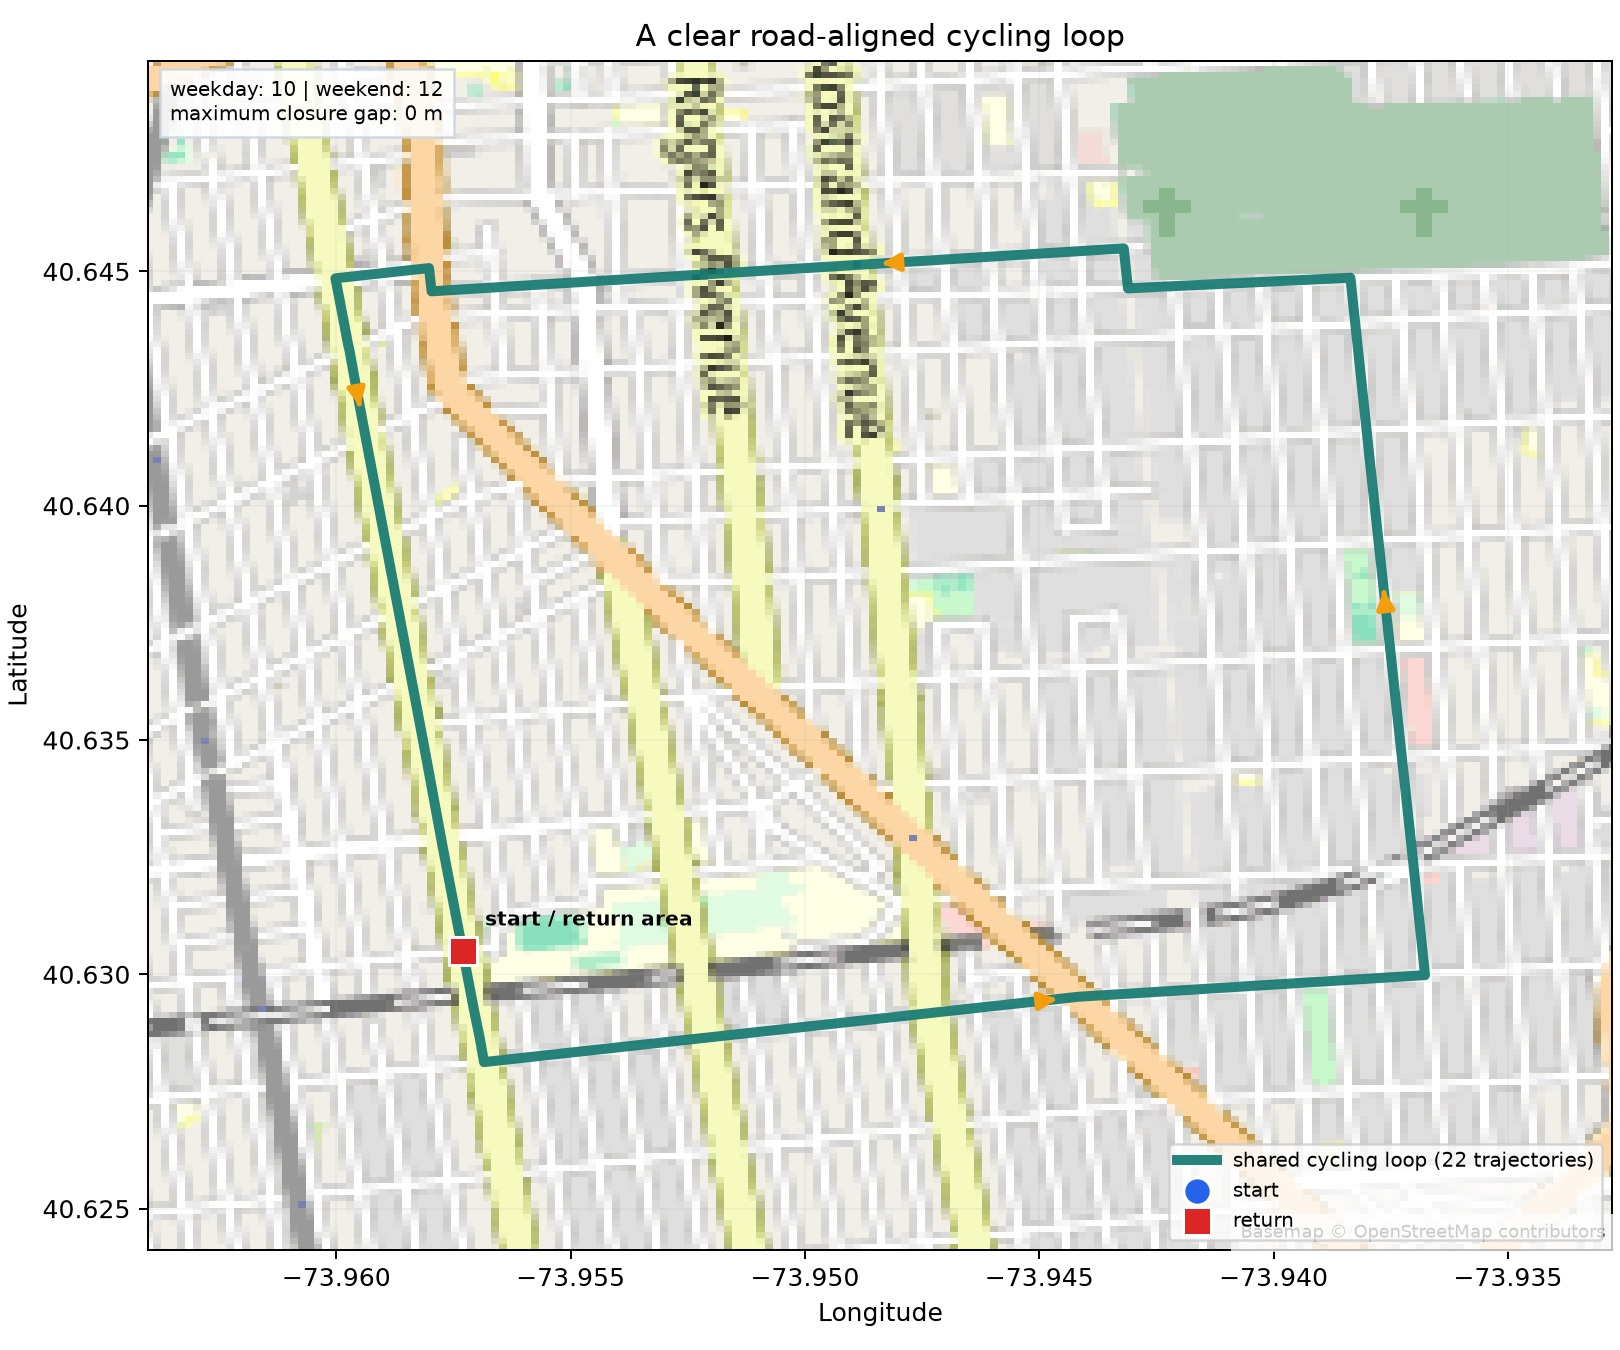

In [ ]:
c = df[df.travel_mode.eq("cycling")].copy()
print(pd.crosstab(df.day_type, df.travel_mode, normalize="index").cycling)
print(c.groupby("day_type").size())
print(
    c[["trajectory_id", "day_type", "route_is_loop", "straight_line_distance_km"]].head(
        20
    )
)
print("all flagged loops", c.route_is_loop.all())
c.groupby("day_type").size().plot.bar()
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex20_insight_4",
  "insight": "Cycling trajectories are occasional on both weekdays and weekends, always follow a loop route.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_4.png"
    ],
    "title": "Weekday and Weekend Mode Patterns: Insight 4",
    "description": "The map uses NYC road geometry, including the non-retracing cycling loop routed over OpenStreetMap roads; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Are cycling trips occasional on both day types, and do all of them return to their starting area?",
  "actionable_insight": "Measure cycling shares and verify start-to-end closure for every cycling trajectory.",
  "code": "c=df[df.travel_mode.eq('cycling')].copy(); print(pd.crosstab(df.day_type,df.travel_mode,normalize='index').cycling); print(c.groupby('day_type').size()); print(c[['trajectory_id','day_type','route_is_loop','straight_line_distance_km']].head(20)); print('all flagged loops',c.route_is_loop.all()); c.groupby('day_type').size().plot.bar(); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "transport_mode",
    "gps_position",
    "matched_road_position"
  ]
}

### Summary of Findings (Flag 20)

Car trips dominate weekday travel, while walking accounts for a noticeably larger share of trips on weekends.  Weekday car trips are longer and occur within more concentrated time periods, whereas weekend car trips are shorter and distributed more broadly across the day. Weekend walking trips cover a wider spatial range than weekday walking trips, despite maintaining similarly low travel speeds. Cycling trajectories are occasional on both weekdays and weekends, always follow a loop route.